# ECG Signal Processing
### From a raw heartbeat recording to a clean image

---

Every person's heartbeat has a slightly different shape — like a fingerprint. This notebook takes raw ECG recordings and turns them into clean, comparable images that a model can later use to recognise people.

We go through four stages for each person:

| Stage | What happens |
|---|---|
| **1 — Raw signal** | The original electrical recording from the heart |
| **2 — Individual beats** | Each heartbeat is cut out and lined up at the same point |
| **3 — Time-frequency image** | The beat is analysed across different frequency bands |
| **4 — Line image** | Only the strongest patterns are kept as clean lines |

The line images from Stage 4 are saved to disk and used in the identity notebook.

---
## Step 1 — Install & Import Libraries

Install and load all the tools this notebook needs. This only needs to run once.

In [21]:
%pip install --quiet numpy matplotlib pywavelets neurokit2 wfdb


[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pywt
import wfdb
import neurokit2 as nk

print('Libraries loaded.')

Libraries loaded.


---
## Step 2 — Settings

All the numbers that control how the notebook runs are kept here in one place. You can change `NUM_SUBJECTS`, `GRID_SUBJECTS`, or `GRID_BEATS` to process more or fewer people and see more or fewer beats in the plots.

In [23]:
# ── Where to save output files ───────────────────────────────
OUT_DIR   = './ecg_morlet_wtmm'
IMAGE_DIR = './ecg_wtmm_images'
os.makedirs(OUT_DIR,   exist_ok=True)
os.makedirs(IMAGE_DIR, exist_ok=True)

# ── How many people and beats to process ────────────────────
NUM_SUBJECTS  = 10   # total people to load from the database
GRID_SUBJECTS = 6    # columns in the grid plots (must be <= NUM_SUBJECTS)
GRID_BEATS    = 6    # rows in the grid plots (beats per person shown)

# ── Beat window around each heartbeat peak ───────────────────
PRE_MS     = 250     # milliseconds before the peak
POST_MS    = 450     # milliseconds after the peak
FS_DEFAULT = 500     # fallback sample rate (Hz) if not in the file

# ── Wavelet analysis settings ────────────────────────────────
WAVELET_NAME = 'morl'   # Morlet wavelet
FREQ_MIN     = 1.0      # lowest frequency to analyse (Hz)
FREQ_MAX     = 60.0     # highest frequency to analyse (Hz)
N_FREQS      = 80       # number of frequency steps
CUT_FREQ     = 5.0      # lowest frequency shown in line images (Hz)

print('Settings ready.')

Settings ready.


---
## Step 3 — Helper Functions

Three small tools used throughout the notebook:

- **`detect_rpeaks`** — cleans the noisy ECG signal and finds the location of each heartbeat peak
- **`extract_beats`** — cuts a short window around every peak so beats can be compared side by side
- **`compute_wtmm_lines`** — traces the strongest ridgelines in the time-frequency image (these become the line images)

In [24]:
def detect_rpeaks(sig, fs):
    """Clean the ECG and return heartbeat peak locations."""
    signals, info = nk.ecg_process(sig, sampling_rate=fs)
    cleaned = signals['ECG_Clean'].values
    r_idx   = info['ECG_R_Peaks']
    return np.array(r_idx), cleaned


def extract_beats(cleaned, r_idx, fs):
    """Cut one window per heartbeat and return them as a 2D array."""
    pre_s, post_s = PRE_MS / 1000., POST_MS / 1000.
    epochs = nk.epochs_create(cleaned, events=r_idx, sampling_rate=fs,
                               epochs_start=-pre_s, epochs_end=post_s)
    keys  = sorted(epochs.keys(), key=lambda k: int(k))
    beats = np.array([epochs[k]['Signal'].values for k in keys])
    return beats, np.linspace(-pre_s, post_s, beats.shape[1])


def compute_wtmm_lines(power, scales, min_len=2):
    """Find and connect the strongest ridgelines in the time-frequency image."""
    n_scales, n_times = power.shape
    mask = np.zeros_like(power, dtype=bool)

    for s in range(n_scales):
        r = power[s]
        if n_times >= 3:
            mask[s, 1:-1] = (r[1:-1] > r[:-2]) & (r[1:-1] > r[2:])
        if n_times >= 2:
            mask[s, 0]  = r[0] > r[1]
            mask[s, -1] = r[-1] > r[-2]
        else:
            mask[s, 0]  = True

    maxima_idx = [np.where(mask[s])[0].tolist() for s in range(n_scales)]
    used, lines = [set() for _ in range(n_scales)], []

    for s0 in range(n_scales):
        for t0 in maxima_idx[s0]:
            if t0 in used[s0]: continue
            line = [(s0, t0)]; used[s0].add(t0); prev_t = t0
            for s in range(s0 + 1, n_scales):
                tol   = max(1, int(round(scales[s] / 2.0)))
                cands = [tt for tt in maxima_idx[s]
                         if tt not in used[s] and abs(int(tt) - int(prev_t)) <= tol]
                if not cands: break
                nxt = min(cands, key=lambda x: abs(x - prev_t))
                line.append((s, int(nxt))); used[s].add(int(nxt)); prev_t = int(nxt)
            if len(line) >= min_len: lines.append(line)

    return lines


print('Helper functions ready.')

Helper functions ready.


---
## Step 4 — Load the ECG Database

We use the publicly available **ECG-ID database**, which contains ECG recordings from 90 people. The first time you run this cell it will download the data automatically. After that it loads from disk.

For each person we find all heartbeat peaks and save the individual beat windows.

In [25]:
if not os.path.exists('./ecgiddb'):
    print('Downloading ECG-ID database — this may take a few minutes ...')
    wfdb.dl_database('ecgiddb', './ecgiddb')
else:
    print('Database already on disk — skipping download.')

cf = pywt.central_frequency(WAVELET_NAME)

all_subjects_signals = {}
all_subjects_beats   = {}
all_subjects_t_beat  = {}
all_subjects_fs      = {}

for subj_idx in range(NUM_SUBJECTS):
    subj_num = subj_idx + 1
    rec_name = f'./ecgiddb/Person_{subj_num:02d}/rec_1'
    print(f'\n→ Person {subj_num:02d}', end='  ')

    try:
        rec = wfdb.rdrecord(rec_name)
    except Exception as e:
        print(f'Could not read file: {e}'); continue

    try:    sig = rec.p_signal[:, 0]
    except: sig = np.asarray(rec.p_signal).flatten()
    fs = getattr(rec, 'fs', FS_DEFAULT) or FS_DEFAULT

    r_idx, cleaned = detect_rpeaks(sig, fs)
    beats, t_beat  = extract_beats(cleaned, r_idx, fs)
    print(f'{len(r_idx)} peaks found  →  {beats.shape[0]} beats saved  (sample rate: {fs} Hz)')

    all_subjects_signals[subj_idx] = sig
    all_subjects_beats[subj_idx]   = beats
    all_subjects_t_beat[subj_idx]  = t_beat
    all_subjects_fs[subj_idx]      = fs

print('\n✓ All people loaded.')

Database already on disk — skipping download.

→ Person 01  24 peaks found  →  24 beats saved  (sample rate: 500 Hz)

→ Person 02  23 peaks found  →  23 beats saved  (sample rate: 500 Hz)

→ Person 03  25 peaks found  →  25 beats saved  (sample rate: 500 Hz)

→ Person 04  23 peaks found  →  23 beats saved  (sample rate: 500 Hz)

→ Person 05  18 peaks found  →  18 beats saved  (sample rate: 500 Hz)

→ Person 06  26 peaks found  →  26 beats saved  (sample rate: 500 Hz)

→ Person 07  27 peaks found  →  27 beats saved  (sample rate: 500 Hz)

→ Person 08  29 peaks found  →  29 beats saved  (sample rate: 500 Hz)

→ Person 09  20 peaks found  →  20 beats saved  (sample rate: 500 Hz)

→ Person 10  28 peaks found  →  28 beats saved  (sample rate: 500 Hz)

✓ All people loaded.


---
## Step 5 — View the Raw ECG Signals

This is what comes directly out of the sensor — a continuous electrical recording of the heart. Each spike is one heartbeat. Notice that the rhythm and shape look slightly different for each person even at this early stage.

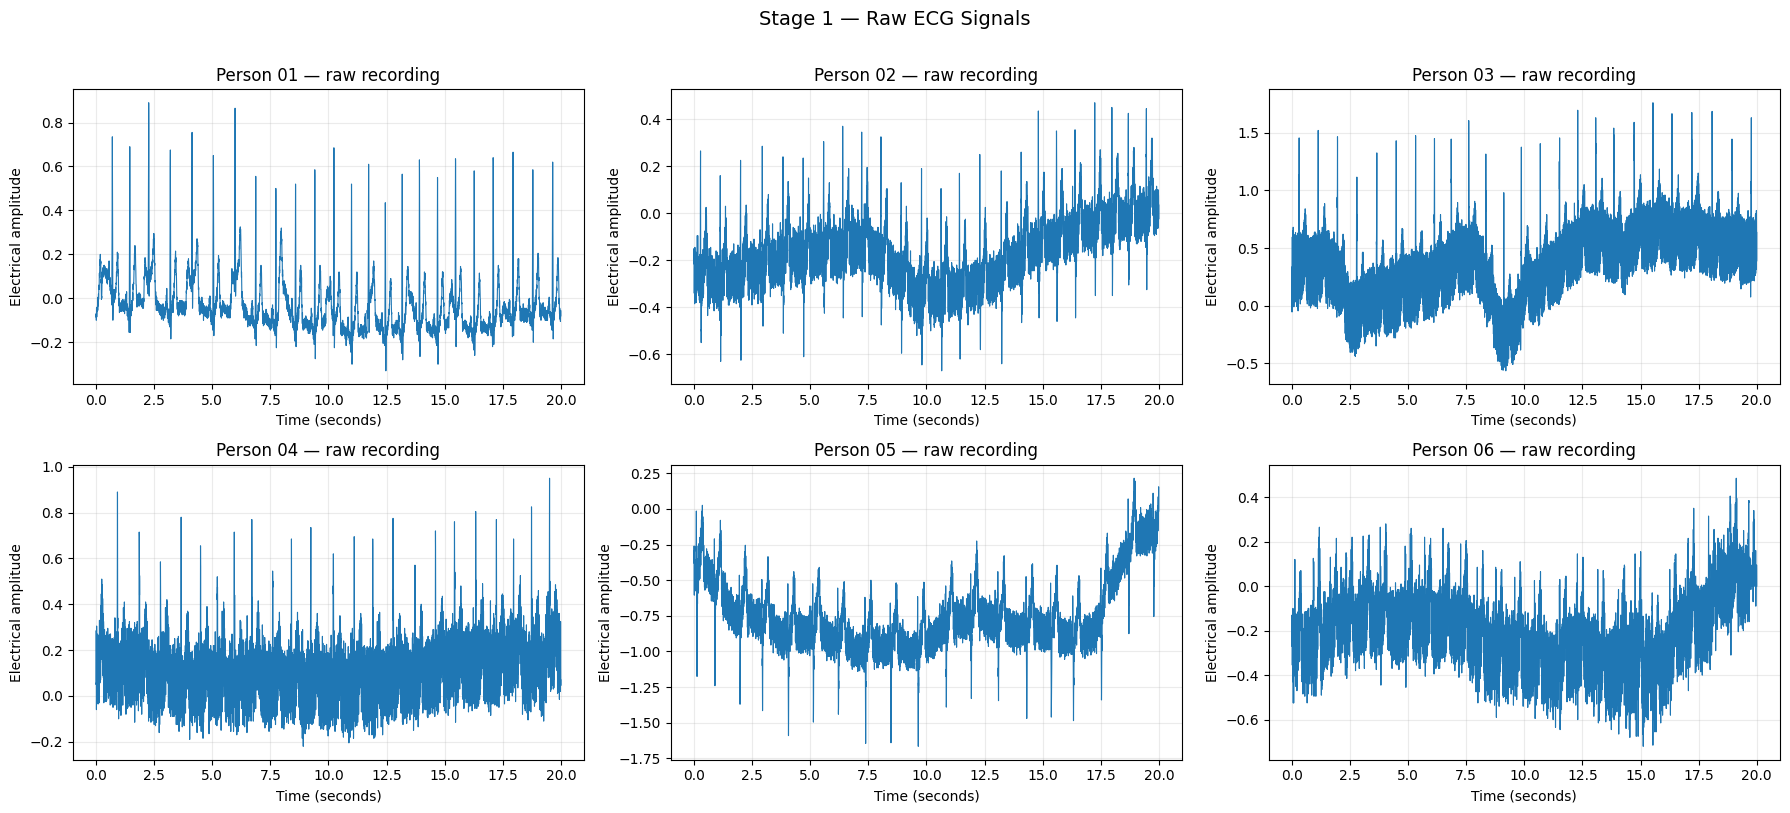

In [26]:
n_show = min(GRID_SUBJECTS, len(all_subjects_signals))
ncols  = min(3, n_show)
nrows  = int(np.ceil(n_show / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4), squeeze=False)
axes      = axes.flatten()

for i in range(n_show):
    sig = all_subjects_signals[i]
    fs  = all_subjects_fs[i]
    ax  = axes[i]
    ax.plot(np.arange(len(sig)) / fs, sig, lw=0.8)
    ax.set_title(f'Person {i+1:02d} — raw recording')
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Electrical amplitude')
    ax.grid(alpha=0.25)

for ax in axes[n_show:]: ax.axis('off')

plt.suptitle('Stage 1 — Raw ECG Signals', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'original_signals_grid.png'), dpi=220)
plt.show()

---
## Step 6 — View the Individual Beats

Each panel is one heartbeat, cut from the recording and lined up so all peaks sit at the same position (the dashed line). This makes it easy to compare the shape of beats from different people or across multiple beats from the same person.

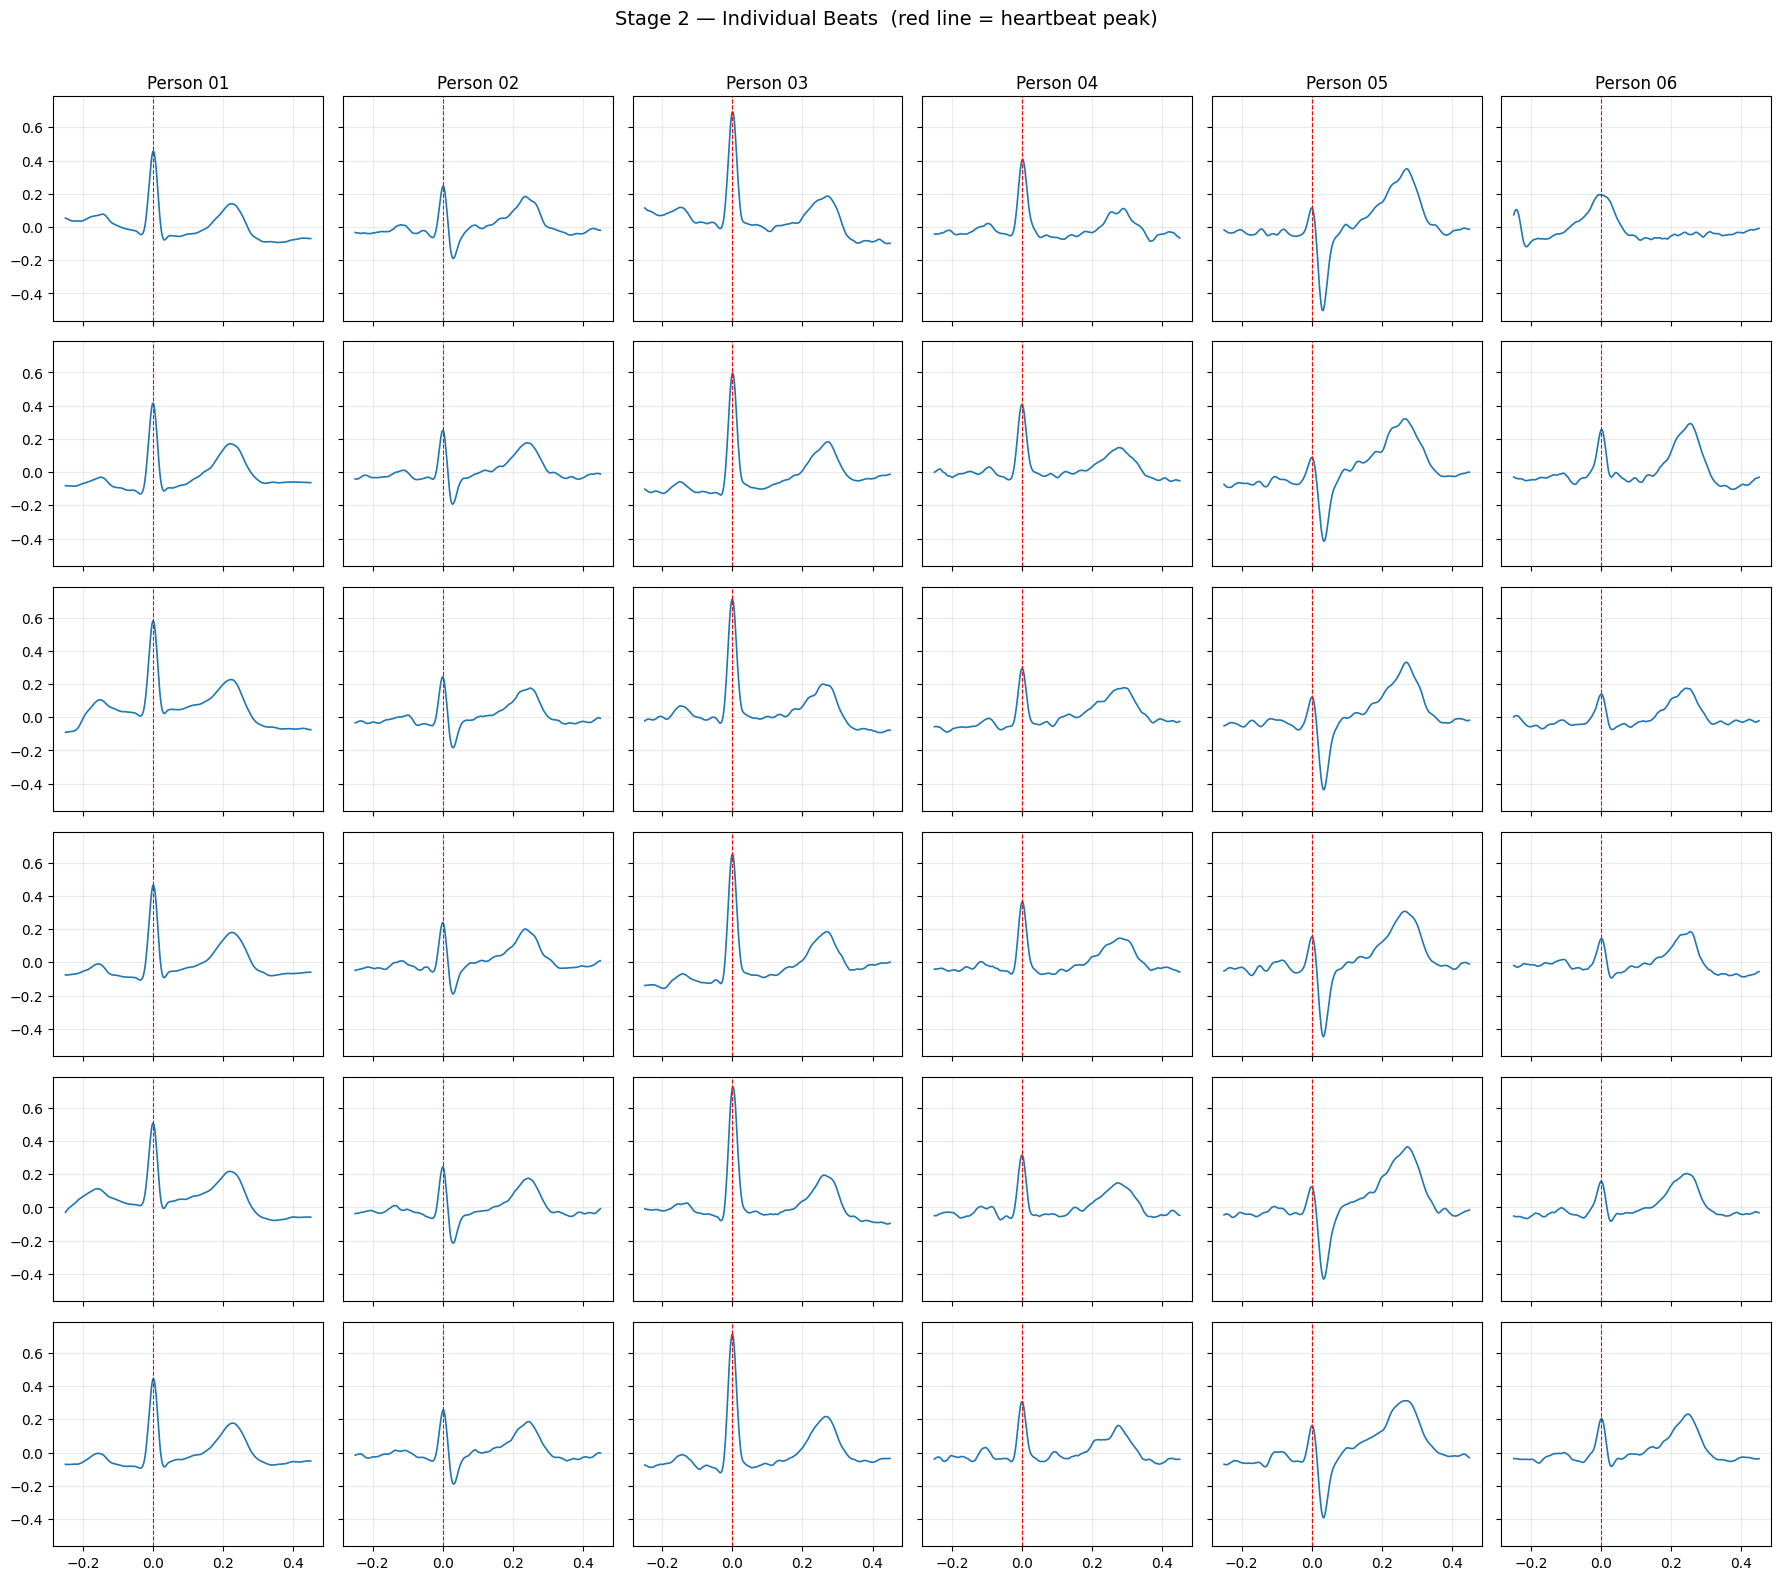

In [27]:
fig, axes = plt.subplots(GRID_BEATS, n_show,
                          figsize=(3 * n_show, 2.6 * GRID_BEATS),
                          squeeze=False, sharex=True, sharey=True)

for col in range(n_show):
    beats  = all_subjects_beats.get(col, np.empty((0,)))
    t_beat = all_subjects_t_beat.get(col)
    for row in range(GRID_BEATS):
        ax = axes[row, col]
        if row < beats.shape[0]:
            ax.plot(t_beat, beats[row], lw=1.2)
            ax.axvline(0, linestyle='--', lw=0.8, color='red')
            ax.grid(alpha=0.25)
            if row == 0: ax.set_title(f'Person {col+1:02d}')
        else:
            ax.axis('off')

plt.suptitle('Stage 2 — Individual Beats  (red line = heartbeat peak)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'extracted_beats_grid.png'), dpi=220)
plt.show()

---
## Step 7 — View the Time-Frequency Images

Instead of just looking at the waveform, we now look at the same beat through many frequency lenses at once. The result is a coloured map where:
- the **horizontal axis** is time (left to right across the beat)
- the **vertical axis** is frequency (low at the bottom, high at the top)
- **brighter colour** means stronger signal energy at that time and frequency

This gives a much richer picture of each beat's structure.

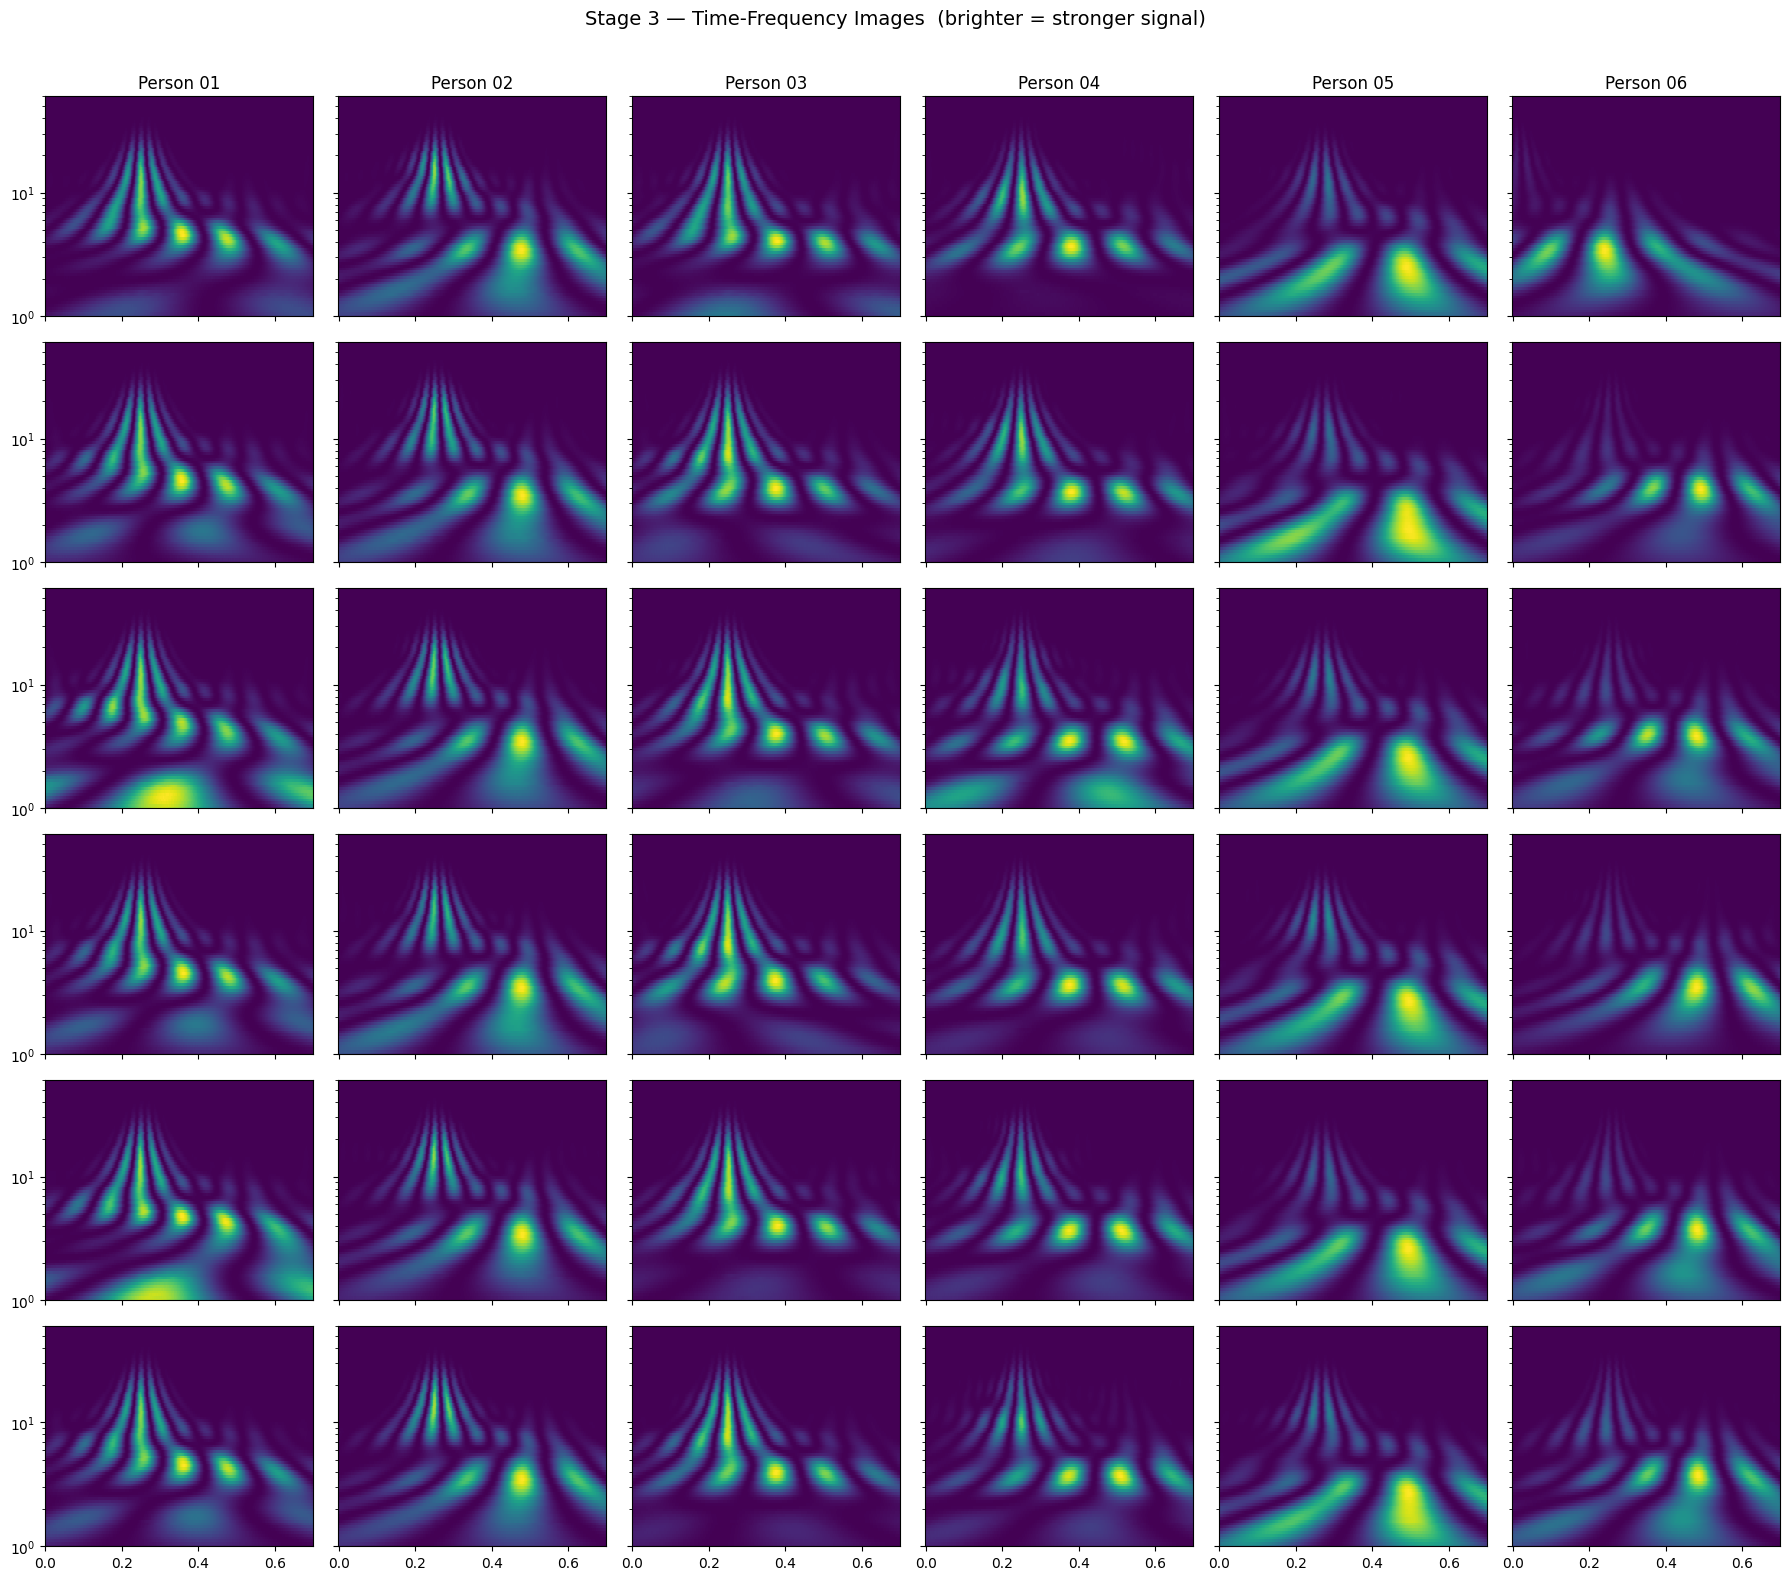

In [28]:
fig, axes = plt.subplots(GRID_BEATS, n_show,
                          figsize=(3 * n_show, 2.6 * GRID_BEATS),
                          squeeze=False, sharex=True, sharey=True)

for col in range(n_show):
    beats = all_subjects_beats.get(col, np.empty((0,)))
    fs    = all_subjects_fs.get(col, FS_DEFAULT)
    freqs = np.logspace(np.log10(FREQ_MIN), np.log10(FREQ_MAX), N_FREQS)
    scales = cf * fs / freqs
    for row in range(GRID_BEATS):
        ax = axes[row, col]
        if row < beats.shape[0]:
            coeffs, freqs_out = pywt.cwt(beats[row], scales, WAVELET_NAME, sampling_period=1./fs)
            power = np.abs(coeffs) ** 2
            T, F  = np.meshgrid(np.arange(beats[row].size) / fs, freqs_out)
            ax.pcolormesh(T, F, power, shading='auto')
            ax.set_yscale('log')
            ax.set_ylim([FREQ_MIN, FREQ_MAX])
            if row == 0: ax.set_title(f'Person {col+1:02d}')
        else:
            ax.axis('off')

plt.suptitle('Stage 3 — Time-Frequency Images  (brighter = stronger signal)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'morlet_scalograms_grid.png'), dpi=220)
plt.show()

---
## Step 8 — Save the Line Images

The full colour image contains a lot of information, but most of it is noise. Here we keep only the strongest ridgelines — the paths of peak energy through the image. The result is a simple line drawing that captures the essential shape of each beat without the clutter.

One image is saved per beat, organised by person. These images are the compact "heartbeat fingerprints" used in the identity notebook.

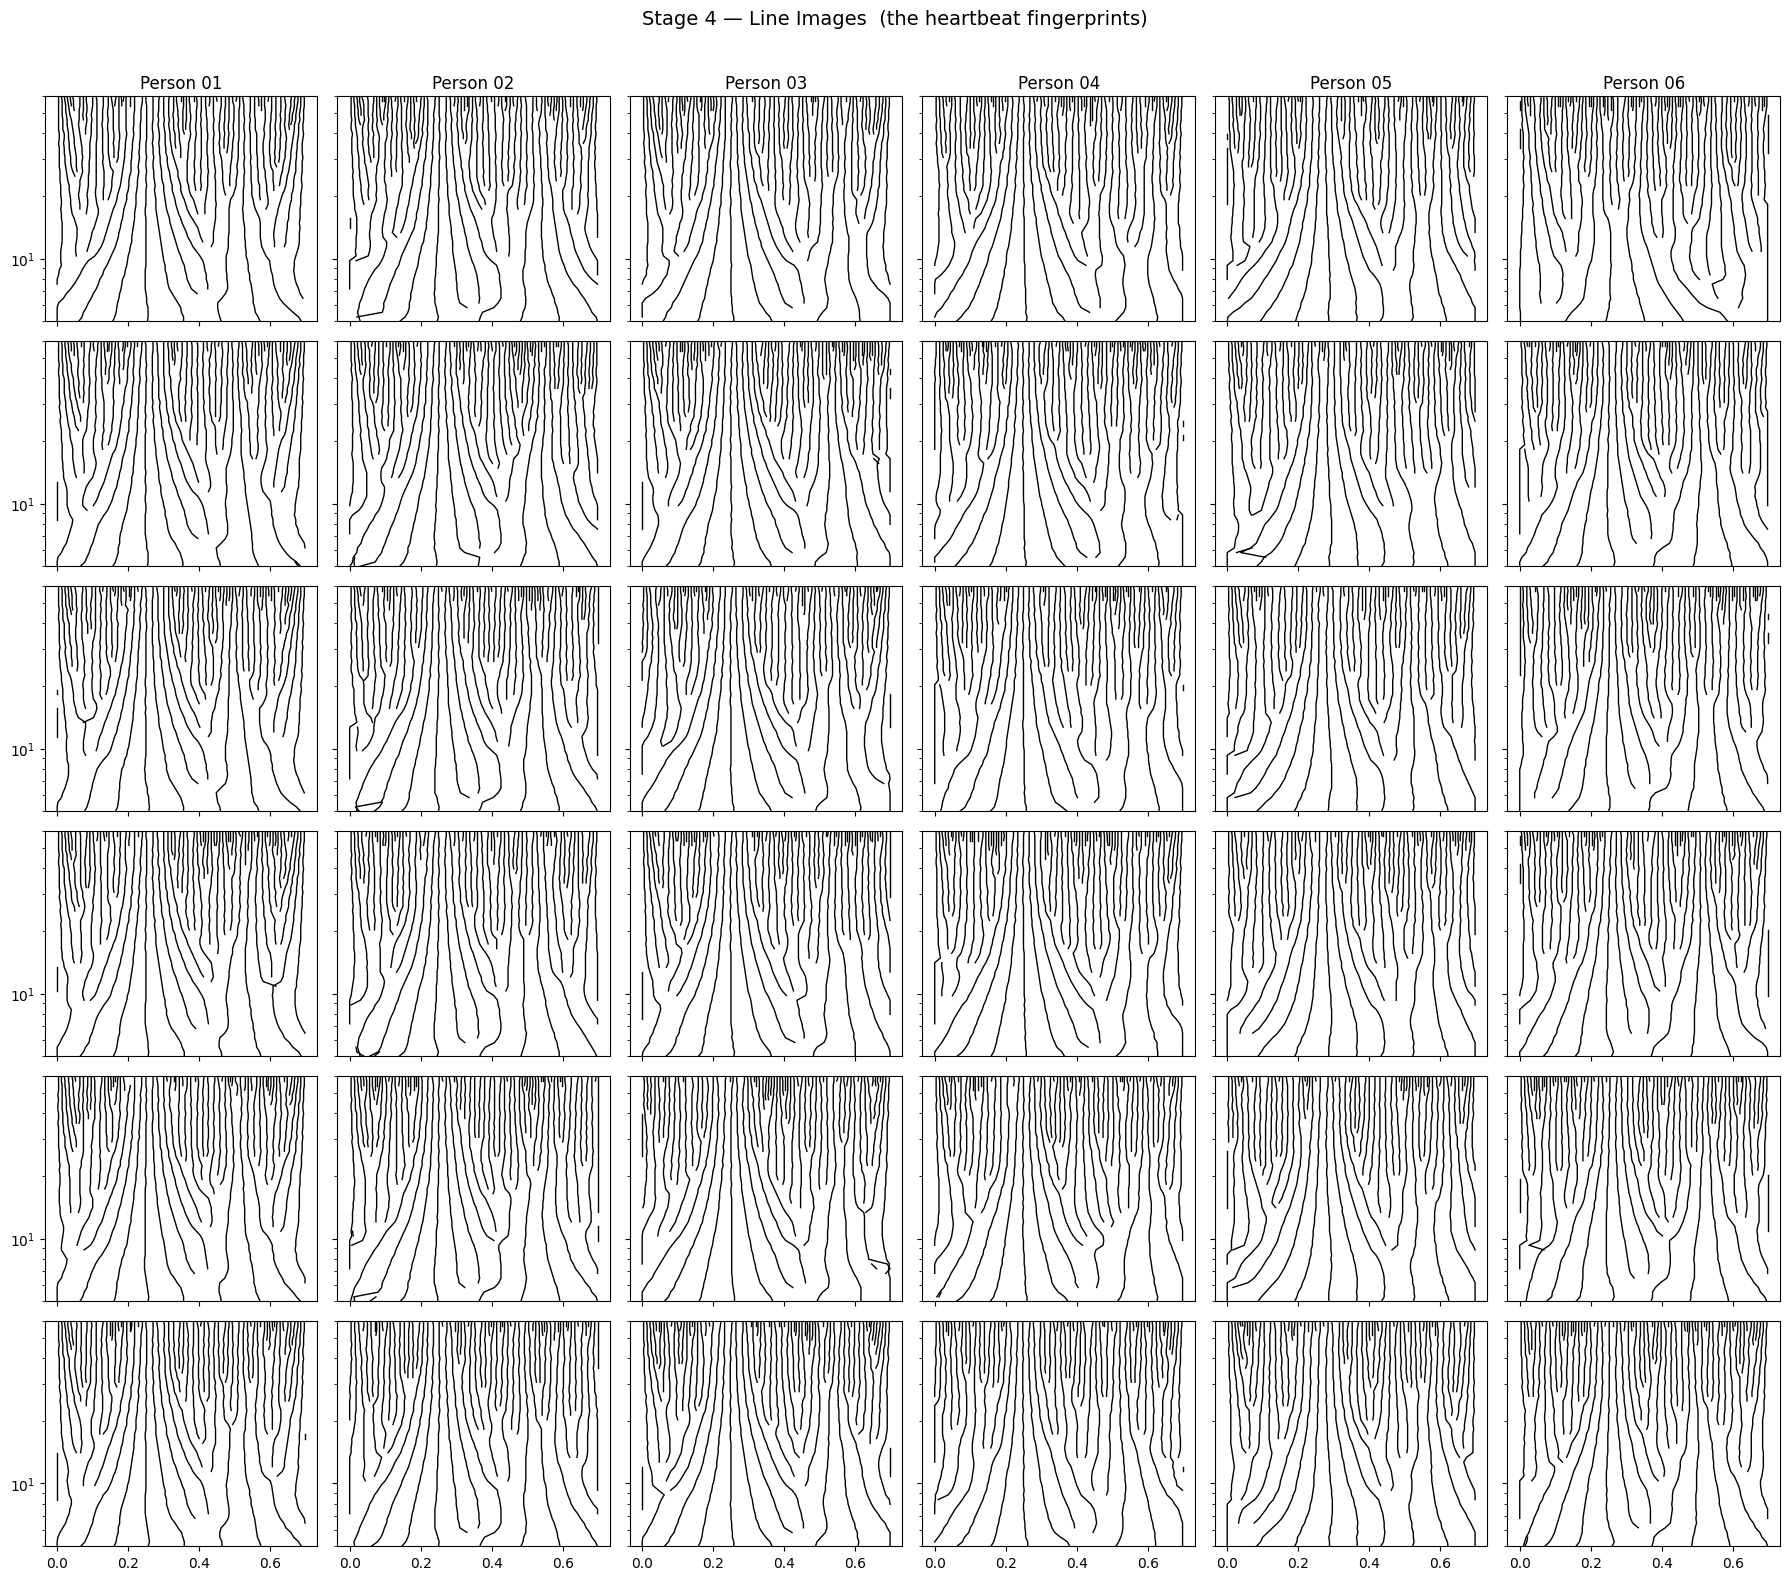


✓ Line images saved to: ./ecg_wtmm_images
  Grid shows first 6 people × first 6 beats each.


In [29]:
fig, axes = plt.subplots(GRID_BEATS, n_show,
                          figsize=(3 * n_show, 2.6 * GRID_BEATS),
                          squeeze=False, sharex=True, sharey=True)

for subj_idx in range(NUM_SUBJECTS):
    subj_num = subj_idx + 1
    beats = all_subjects_beats.get(subj_idx, np.empty((0,)))
    if beats.size == 0:
        print(f'Person {subj_num:02d}: no beats found, skipping.')
        continue

    fs     = all_subjects_fs.get(subj_idx, FS_DEFAULT)
    freqs  = np.logspace(np.log10(FREQ_MIN), np.log10(FREQ_MAX), N_FREQS)
    scales = cf * fs / freqs

    subj_dir = os.path.join(IMAGE_DIR, f'subject_{subj_num:02d}')
    os.makedirs(subj_dir, exist_ok=True)

    # Save one clean line image per beat (used later as the ML dataset)
    for b_idx in range(beats.shape[0]):
        coeffs, freqs_out = pywt.cwt(beats[b_idx], scales, WAVELET_NAME, sampling_period=1./fs)
        power = np.abs(coeffs) ** 2
        lines = compute_wtmm_lines(power, scales)

        fig_ind, ax_ind = plt.subplots(figsize=(3, 3))
        for line in lines:
            xs = [t / fs for _, t in line]
            ys = [freqs_out[s] for s, _ in line]
            ax_ind.plot(xs, ys, '-', lw=1.0)
        ax_ind.set_yscale('log')
        ax_ind.set_ylim([CUT_FREQ, max(freqs_out)])
        ax_ind.axis('off')
        plt.savefig(os.path.join(subj_dir, f'wtmm_beat_{b_idx+1:03d}.png'),
                    bbox_inches='tight', pad_inches=0)
        plt.close(fig_ind)

    # Add the first few beats to the grid display
    if subj_idx < n_show:
        for row in range(GRID_BEATS):
            ax = axes[row, subj_idx]
            if row < beats.shape[0]:
                coeffs, freqs_out = pywt.cwt(beats[row], scales, WAVELET_NAME, sampling_period=1./fs)
                power = np.abs(coeffs) ** 2
                lines = compute_wtmm_lines(power, scales)
                for line in lines:
                    ax.plot([t / fs for _, t in line],
                            [freqs_out[s] for s, _ in line], '-', color='black', lw=1.0)
                ax.set_yscale('log')
                ax.set_ylim([CUT_FREQ, max(freqs_out)])
                if row == 0: ax.set_title(f'Person {subj_idx+1:02d}')
            else:
                ax.axis('off')

plt.suptitle('Stage 4 — Line Images  (the heartbeat fingerprints)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'wtmm_lines_grid.png'), dpi=220)
plt.show()

print(f'\n✓ Line images saved to: {IMAGE_DIR}')
print(f'  Grid shows first {n_show} people × first {GRID_BEATS} beats each.')

---
## Step 9 — One Beat, All Four Stages

Finally, let's follow a single beat from one person through all four stages in full size. Change `PERSON` or `BEAT` to look at a different example.

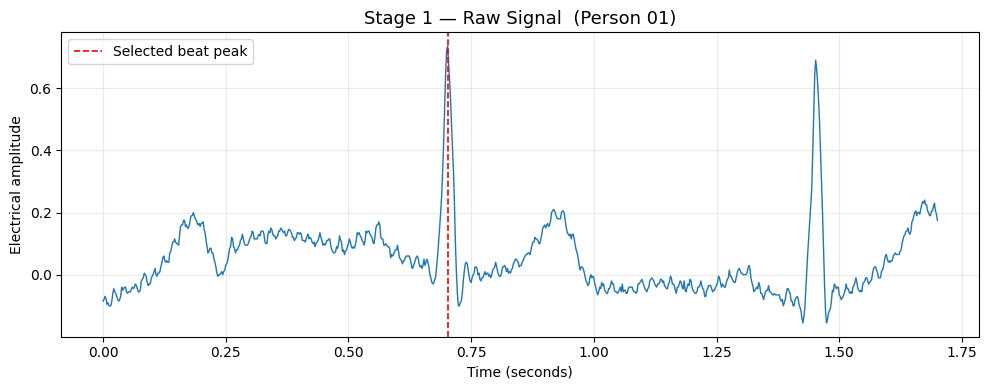

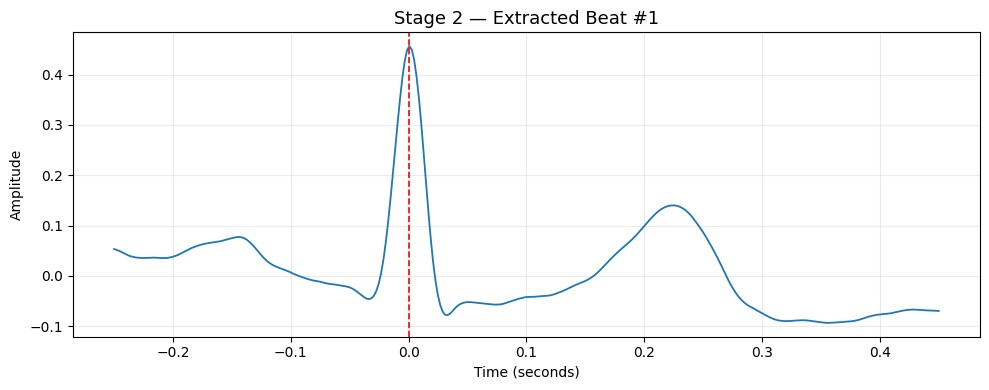

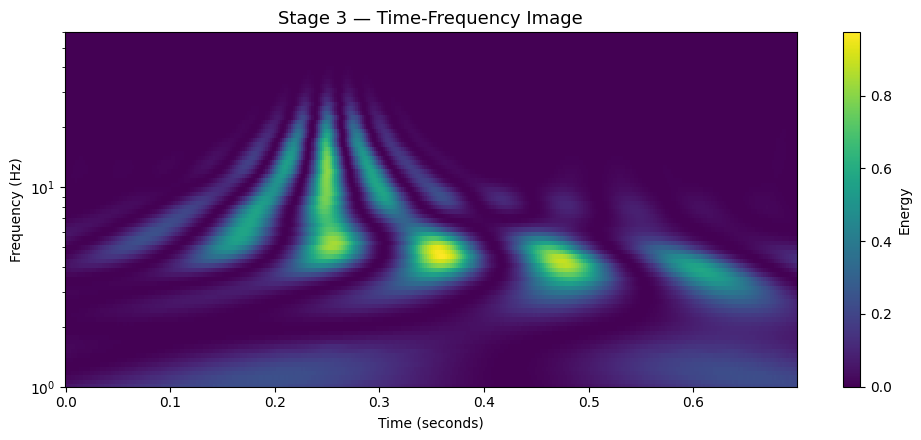

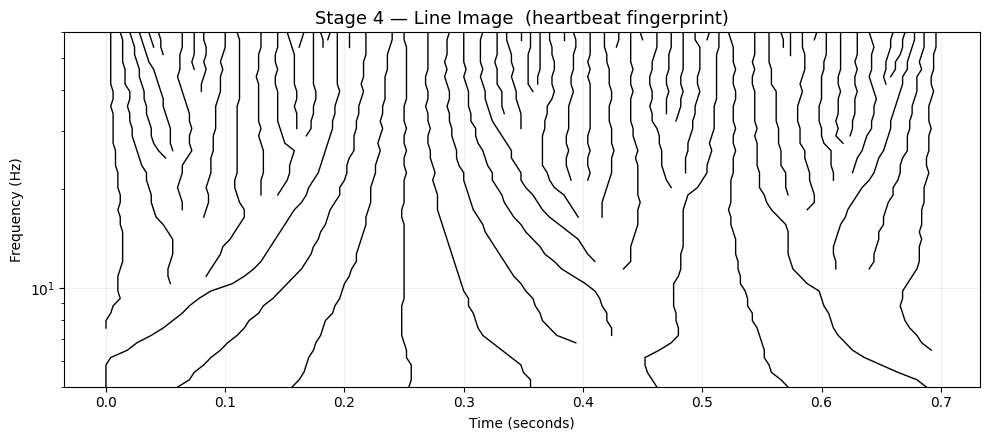

In [30]:
PERSON = 1   # which person to show (1-based)
BEAT   = 1   # which beat to show   (1-based)

# ── Fetch data for the chosen person ────────────────────────
subj_idx = PERSON - 1
if subj_idx not in all_subjects_signals:
    raise ValueError(f'Person {PERSON:02d} was not loaded. Check NUM_SUBJECTS.')

sig = all_subjects_signals[subj_idx]
fs  = all_subjects_fs[subj_idx]
r_idx, cleaned = detect_rpeaks(sig, fs)

beat_idx  = min(max(BEAT - 1, 0), len(r_idx) - 1)
beats_one, t_beat = extract_beats(cleaned, np.array([r_idx[beat_idx]]), fs)
beat = beats_one[0]

freqs     = np.logspace(np.log10(FREQ_MIN), np.log10(FREQ_MAX), N_FREQS)
scales    = cf * fs / freqs
coeffs, freqs_out = pywt.cwt(beat, scales, WAVELET_NAME, sampling_period=1./fs)
power     = np.abs(coeffs) ** 2
lines     = compute_wtmm_lines(power, scales)

# ── Stage 1: raw signal around this beat ────────────────────
center = r_idx[beat_idx]
win    = int(round(1.0 * fs))
s_win, e_win = max(0, center - win), min(len(sig), center + win)
t_sig  = np.arange(len(sig)) / fs

plt.figure(figsize=(10, 4))
plt.plot(t_sig[s_win:e_win], sig[s_win:e_win], lw=1.0)
plt.axvline(center / fs, linestyle='--', lw=1.2, color='red', label='Selected beat peak')
plt.title(f'Stage 1 — Raw Signal  (Person {PERSON:02d})', fontsize=13)
plt.xlabel('Time (seconds)'); plt.ylabel('Electrical amplitude')
plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

# ── Stage 2: extracted beat ──────────────────────────────────
plt.figure(figsize=(10, 4))
plt.plot(t_beat, beat, lw=1.3)
plt.axvline(0, linestyle='--', lw=1.2, color='red')
plt.title(f'Stage 2 — Extracted Beat #{beat_idx+1}', fontsize=13)
plt.xlabel('Time (seconds)'); plt.ylabel('Amplitude')
plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

# ── Stage 3: time-frequency image ───────────────────────────
T, F = np.meshgrid(np.arange(beat.size) / fs, freqs_out)
plt.figure(figsize=(10, 4.5))
plt.pcolormesh(T, F, power, shading='auto')
plt.yscale('log'); plt.ylim([FREQ_MIN, FREQ_MAX])
plt.title('Stage 3 — Time-Frequency Image', fontsize=13)
plt.xlabel('Time (seconds)'); plt.ylabel('Frequency (Hz)')
plt.colorbar(label='Energy'); plt.tight_layout(); plt.show()

# ── Stage 4: line image ──────────────────────────────────────
plt.figure(figsize=(10, 4.5))
for line in lines:
    plt.plot([t / fs for _, t in line], [freqs_out[s] for s, _ in line],
             '-', color='black', lw=1.0)
plt.yscale('log'); plt.ylim([CUT_FREQ, max(freqs_out)])
plt.title('Stage 4 — Line Image  (heartbeat fingerprint)', fontsize=13)
plt.xlabel('Time (seconds)'); plt.ylabel('Frequency (Hz)')
plt.grid(alpha=0.2); plt.tight_layout(); plt.show()